<a href="https://colab.research.google.com/github/loveyourz-s/CV-scanner/blob/main/ScannerProject(KuresbayAkbotaDS_23b).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

Успешно загружено!


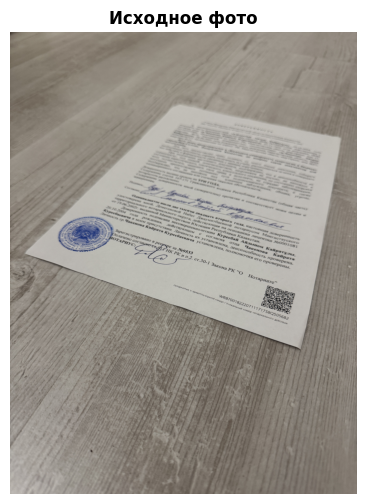

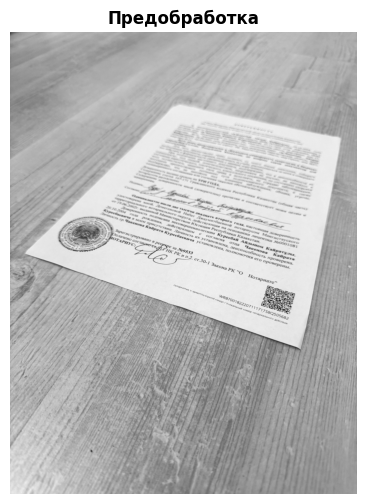

In [16]:
filename = 'IMG_0259.JPG'

image = cv2.imread(filename)

if image is None:
    print(f"Ошибка: Файл '{filename}' не найден!")
else:
    print(f"Успешно загружено!")

    def show_image(img, title=""):
        plt.figure(figsize=(6, 6))
        if len(img.shape) == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(img, cmap='gray')
        plt.title(title, fontweight='bold')
        plt.axis('off')
        plt.show()

    show_image(image, "Исходное фото")


    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    show_image(blurred, "Предобработка")

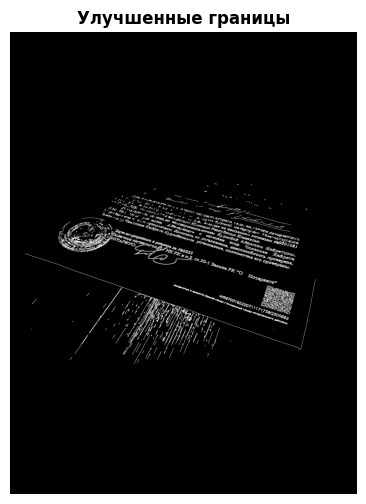

Контур не найден.


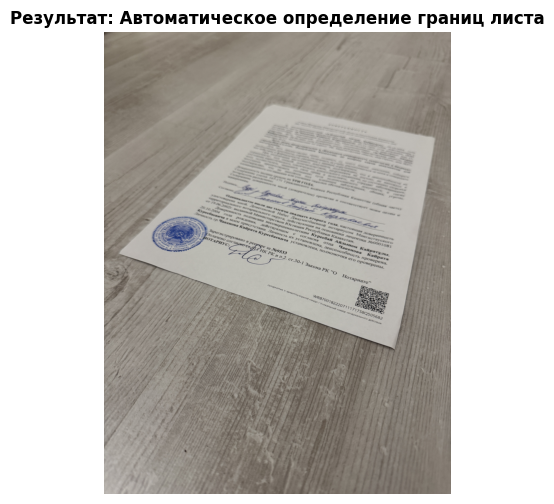

In [17]:
edged = cv2.Canny(blurred, 50, 150)

# 2. Утолщаем линии (морфологическое закрытие), чтобы соединить разрывы в границах
kernel = np.ones((3, 3), np.uint8)
edged = cv2.dilate(edged, kernel, iterations=1)

show_image(edged, "Улучшенные границы")

# 3. Ищем контуры
contours, _ = cv2.findContours(edged.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = sorted(contours, key=cv2.contourArea, reverse=True)[:10]

document_contour = None

# 4. Ищем контур с 4 углами
for c in contours:
    perimeter = cv2.arcLength(c, True)
    approx = cv2.approxPolyDP(c, 0.02 * perimeter, True)

    # Проверяем, что контур достаточно большой по площади (чтобы не ловить мелкие объекты)
    if len(approx) == 4 and cv2.contourArea(c) > 10000:
        document_contour = approx
        break

# 5. Рисуем результат
output_image = image.copy()
if document_contour is not None:
    cv2.drawContours(output_image, [document_contour], -1, (0, 255, 0), 10)
    print("Успешно! Четыре угла документа найдены.")
else:
    print("Контур не найден.")

show_image(output_image, "Результат: Автоматическое определение границ листа")

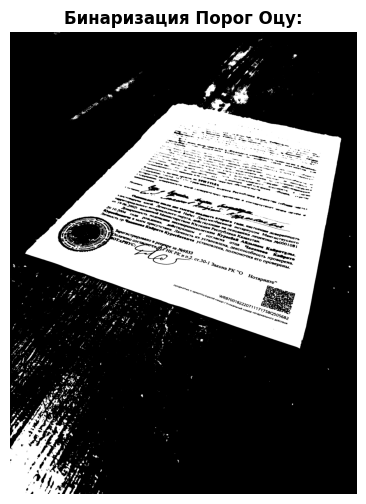

Границы листа успешно обнаружены.


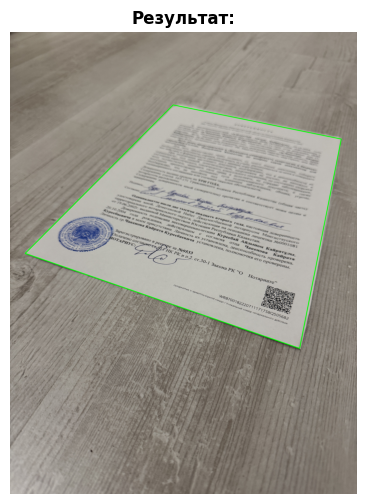

In [18]:
# 1. Переводим в серое и размываем
gray_img = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred_img = cv2.GaussianBlur(gray_img, (7, 7), 0)

# 2. Применяем метод Оцу (автоматический поиск порога для разделения листа и пола)
_, thresh = cv2.threshold(blurred_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
show_image(thresh, "Бинаризация Порог Оцу:")

# 3. Ищем контуры на бинарном изображении
contours, _ = cv2.findContours(thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = sorted(contours, key=cv2.contourArea, reverse=True)

document_contour = None

# 4. Перебираем контуры и ищем самый большой прямоугольник (лист)
for c in contours:
    perimeter = cv2.arcLength(c, True)
    approx = cv2.approxPolyDP(c, 0.02 * perimeter, True)

    # Если найдено 4 угла и площадь контура достаточно большая
    if len(approx) == 4 and cv2.contourArea(c) > 5000:
        document_contour = approx
        break

# 5. Рисуем результат
output_image = image.copy()
if document_contour is not None:

    cv2.drawContours(output_image, [document_contour], -1, (0, 255, 0), 10)
    print("Границы листа успешно обнаружены.")
else:
    print("Контур не найден.")

    if len(contours) > 0:
        rect = cv2.minAreaRect(contours[0])
        box = cv2.boxPoints(rect)
        document_contour = np.int32(box)
        cv2.drawContours(output_image, [document_contour], -1, (0, 255, 0), 10)

show_image(output_image, "Результат:")

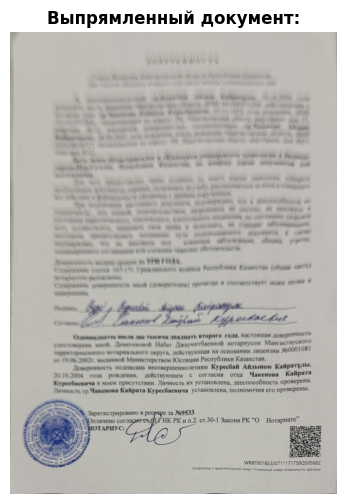

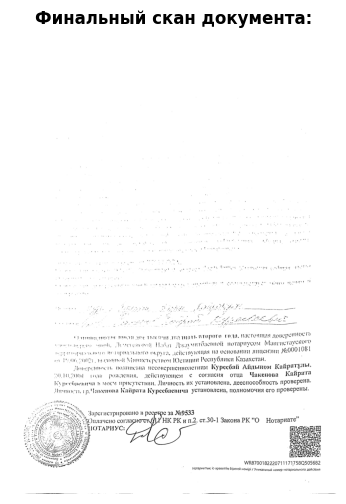

Трансформация перспективы и бинаризация успешно выполнены!


In [21]:
def order_points(pts):

    rect = np.zeros((4, 2), dtype=np.float32)
    s = pts.sum(axis=1)
    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]
    diff = np.diff(pts, axis=1)
    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]
    return rect

def four_point_transform_A4(image, pts):
    rect = order_points(pts.reshape(4, 2))
    (tl, tr, br, bl) = rect

    widthA = np.sqrt(((br[0] - bl[0]) ** 2) + ((br[1] - bl[1]) ** 2))
    widthB = np.sqrt(((tr[0] - tl[0]) ** 2) + ((tr[1] - tl[1]) ** 2))
    maxWidth = max(int(widthA), int(widthB))

    heightA = np.sqrt((tr[0] - br[0]) ** 2 + (tr[1] - br[1]) ** 2)
    heightB = np.sqrt((tl[0] - bl[0]) ** 2 + (tl[1] - bl[1]) ** 2)
    maxHeight = max(int(heightA), int(heightB))

    if maxHeight < maxWidth:
        maxWidth, maxHeight = maxHeight, maxWidth
    maxHeight = int(maxWidth * 1.414)

    dst = np.float32([
        [0, 0],
        [maxWidth - 1, 0],
        [maxWidth - 1, maxHeight - 1],
        [0, maxHeight - 1]
    ])

    M = cv2.getPerspectiveTransform(rect, dst)
    return cv2.warpPerspective(image, M, (maxWidth, maxHeight))

# Проверяем, что контур был найден на предыдущем этапе
if document_contour is not None:
    # 1. Выполняем перспективное преобразование
    scan_result = four_point_transform_A4(image, document_contour)

    # 2. Создаем финальный черно-белый скан (адаптивный порог для текста и печати)
    gray_scan = cv2.cvtColor(scan_result, cv2.COLOR_BGR2GRAY)
    final_scan = cv2.adaptiveThreshold(
        gray_scan, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, 15, 11
    )

    # 3. Выводим результаты
    show_image(scan_result, "Выпрямленный документ:")
    show_image(final_scan, "Финальный скан документа:")
    print("Трансформация перспективы и бинаризация успешно выполнены!")
else:
    print("Ошибка: Переменная 'document_contour' не найдена.")